<a href="https://colab.research.google.com/github/zhanibekbeymbetov-debug/botnet-detection-ctu13/blob/main/c2_host_profiling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [31]:
import re
import pickle
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             precision_recall_curve, roc_curve)

SEED = 42
CTU_DIR = Path("data/ctu13")
CACHE_DIR = Path("cache")
MAX_ROWS = None
COMMON_PORTS = {20, 21, 22, 25, 53, 80, 110, 123, 143, 443, 587, 993, 995}
MIN_PAIR_INTERVALS = 4
REGULAR_CV = 0.15

USECOLS = ["StartTime", "Dur", "Proto", "SrcAddr", "DstAddr", "Dport",
           "TotBytes", "SrcBytes", "Label"]

FEATURES = [
    "log_flows", "log_ndst", "log_ndport", "fanout",
    "short_frac", "no_reply_frac", "odd_port_frac", "log_out_in",
    "n_regular_pairs", "min_pair_cv",
]

In [32]:
def read_flows(path, max_rows=None):
    raw = pd.read_csv(path, usecols=USECOLS, nrows=max_rows, low_memory=False)
    ts = pd.to_datetime(raw["StartTime"], errors="coerce")
    raw = raw[ts.notna()].copy()
    ts = ts[ts.notna()]
    raw["t"] = (ts - ts.min()).dt.total_seconds()
    raw["Dur"] = pd.to_numeric(raw["Dur"], errors="coerce").fillna(0.0)
    raw["TotBytes"] = pd.to_numeric(raw["TotBytes"], errors="coerce").fillna(0)
    raw["SrcBytes"] = pd.to_numeric(raw["SrcBytes"], errors="coerce").fillna(0)
    raw["dport"] = pd.to_numeric(raw["Dport"], errors="coerce").fillna(-1).astype(int)
    raw["Label"] = raw["Label"].fillna("")
    return raw


def host_table(flows):
    """Profile for each source host + label (1 infected, 0 normal, NaN unlabeled)."""
    f = flows
    f = f.assign(
        bytes_in=(f["TotBytes"] - f["SrcBytes"]).clip(lower=0),
        short=(f["Dur"] < 1.0),
        no_reply=((f["TotBytes"] - f["SrcBytes"]).clip(lower=0) == 0),
        odd_port=~f["dport"].isin(COMMON_PORTS),
        is_bot=f["Label"].str.contains("Botnet", na=False),
        is_norm=f["Label"].str.contains("Normal", na=False),
    )
    g = f.groupby("SrcAddr")
    h = pd.DataFrame({
        "n_flows": g.size(),
        "n_dst": g["DstAddr"].nunique(),
        "n_dport": g["dport"].nunique(),
        "short_frac": g["short"].mean(),
        "no_reply_frac": g["no_reply"].mean(),
        "odd_port_frac": g["odd_port"].mean(),
        "out_bytes": g["SrcBytes"].sum(),
        "in_bytes": g["bytes_in"].sum(),
        "has_bot": g["is_bot"].max(),
        "has_norm": g["is_norm"].max(),
    })

    p = f[["SrcAddr", "DstAddr", "t"]].sort_values(["SrcAddr", "DstAddr", "t"])
    p["dt"] = p.groupby(["SrcAddr", "DstAddr"])["t"].diff()
    pair = p.groupby(["SrcAddr", "DstAddr"])["dt"].agg(["count", "mean", "std"]).reset_index()
    pair = pair[(pair["count"] >= MIN_PAIR_INTERVALS) & (pair["mean"] > 0)]
    pair["cv"] = pair["std"] / pair["mean"]
    h["n_regular_pairs"] = pair[pair["cv"] < REGULAR_CV].groupby("SrcAddr").size()
    h["min_pair_cv"] = pair.groupby("SrcAddr")["cv"].min()
    h["n_regular_pairs"] = h["n_regular_pairs"].fillna(0)
    h["min_pair_cv"] = h["min_pair_cv"].fillna(5.0).clip(upper=5.0)

    h["log_flows"] = np.log1p(h["n_flows"])
    h["log_ndst"] = np.log1p(h["n_dst"])
    h["log_ndport"] = np.log1p(h["n_dport"])
    h["fanout"] = h["n_dst"] / h["n_flows"]
    h["log_out_in"] = np.log1p(h["out_bytes"]) - np.log1p(h["in_bytes"])

    h["label"] = np.where(h["has_bot"], 1.0, np.where(h["has_norm"], 0.0, np.nan))
    return h.reset_index().rename(columns={"SrcAddr": "host"})


NAME_RE = re.compile(r"^(\d+)-(.+)-(\d{8})")


def parse_name(path):
    m = NAME_RE.match(path.name)
    if not m:
        return None, path.stem
    return int(m.group(1)), m.group(2)


def load_all(ctu_dir):
    CACHE_DIR.mkdir(exist_ok=True)
    parts = []
    for path in sorted(ctu_dir.rglob("*.binetflow*")):
        scen, fam = parse_name(path)
        cache = CACHE_DIR / f"{path.name}.{MAX_ROWS}.pkl"
        if cache.exists():
            h = pickle.loads(cache.read_bytes())
        else:
            print(f"Processing {path.name} ...")
            h = host_table(read_flows(path, MAX_ROWS))
            cache.write_bytes(pickle.dumps(h))
        h = h.assign(file=path.name, scenario=scen, family=fam)
        parts.append(h)
    return pd.concat(parts, ignore_index=True) if parts else None

In [33]:
all_hosts = load_all(CTU_DIR) if CTU_DIR.exists() else None

if all_hosts is None:
    hosts = None
    print(f"CTU-13 files (*.binetflow or *.binetflow.csv) not found in {CTU_DIR}/. Please place the CTU-13 dataset there and restart the notebook.")
else:
    hosts = all_hosts.dropna(subset=["label"]).copy()
    hosts["label"] = hosts["label"].astype(int)
    summary = (hosts.groupby(["scenario", "family"])["label"]
               .agg(hosts="size", infected="sum").reset_index())
    summary["normal"] = summary["hosts"] - summary["infected"]
    print(f"Files: {all_hosts['file'].nunique()}, labeled hosts: {len(hosts)}, "
          f"infected: {int(hosts['label'].sum())}")
    display(summary)
    no_pos = summary[summary["infected"] == 0]
    if len(no_pos):
        print("Warning: no infected hosts in these scenarios after labeling "
              "(check file names and labels):", list(no_pos["scenario"]))

Files: 13, labeled hosts: 290, infected: 42


,scenario,family,hosts,infected,normal
0,1,Neris,20,1,19
1,2,Neris,15,1,14
2,3,Rbot,25,2,23
3,4,Rbot,23,1,22
4,5,Virut,23,1,22
5,6,Menti,17,1,16
6,7,Sogou,14,1,13
7,8,Murlo,24,1,23
8,9,Neris,35,10,25
9,10,Rbot,28,10,18


In [34]:
if hosts is not None and hosts["label"].nunique() == 2:
    rows = []
    for feat in FEATURES:
        auc = roc_auc_score(hosts["label"], hosts[feat])
        rows.append({
            "feature": feat,
            "AUC": round(auc, 3),
            "power (|AUC-0.5|*2)": round(abs(auc - 0.5) * 2, 3),
            "in_infected": "higher" if auc >= 0.5 else "lower"
        })
    feat_auc = pd.DataFrame(rows).sort_values("power (|AUC-0.5|*2)", ascending=False)
    print("Separating power of each individual feature (all hosts, no training):")
    display(feat_auc)

Separating power of each individual feature (all hosts, no training):


,feature,AUC,power (|AUC-0.5|*2),in_infected
5,no_reply_frac,0.775,0.551,higher
6,odd_port_frac,0.745,0.491,higher
0,log_flows,0.700,0.400,higher
2,log_ndport,0.645,0.291,higher
9,min_pair_cv,0.621,0.242,higher
1,log_ndst,0.608,0.217,higher
7,log_out_in,0.605,0.210,higher
8,n_regular_pairs,0.399,0.202,lower
3,fanout,0.476,0.048,lower
4,short_frac,0.515,0.030,higher


In [35]:
def make_model():
    return make_pipeline(
        StandardScaler(),
        LogisticRegression(class_weight="balanced", C=0.3, max_iter=2000, random_state=SEED),
    )


def pick_threshold(X, y):
    """Threshold based on F1-score via internal cross-validation on training data."""
    n_pos = int(y.sum())
    if n_pos < 2 or n_pos == len(y):
        return 0.5
    cv = StratifiedKFold(n_splits=min(3, n_pos), shuffle=True, random_state=SEED)
    s = cross_val_predict(make_model(), X, y, cv=cv, method="predict_proba")[:, 1]
    prec, rec, thr = precision_recall_curve(y, s)
    f1 = 2 * prec * rec / np.maximum(prec + rec, 1e-12)
    return float(thr[int(np.argmax(f1[:-1]))])


oof = None
if hosts is not None:
    rows, parts = [], []
    families = sorted(hosts["family"].unique())
    for fam in families:
        te = hosts[hosts["family"] == fam]
        tr = hosts[hosts["family"] != fam]
        if tr["label"].sum() < 2 or te["label"].sum() == 0:
            rows.append({
                "family": fam,
                "scenarios": sorted(te["scenario"].unique().tolist()),
                "infected": int(te["label"].sum()),
                "detected": None,
                "missed": None,
                "false_alarms": None,
                "normal": int((te["label"] == 0).sum()),
                "threshold": None,
                "note": "no positive examples in test or train"
            })
            continue
        thr = pick_threshold(tr[FEATURES].values, tr["label"].values)
        model = make_model().fit(tr[FEATURES].values, tr["label"].values)
        s = model.predict_proba(te[FEATURES].values)[:, 1]
        pred = s >= thr
        y = te["label"].values
        tp = int(((y == 1) & pred).sum())
        fn = int(((y == 1) & ~pred).sum())
        fp = int(((y == 0) & pred).sum())
        tn = int(((y == 0) & ~pred).sum())
        rows.append({
            "family": fam,
            "scenarios": sorted(te["scenario"].unique().tolist()),
            "infected": int(y.sum()),
            "detected": tp,
            "missed": fn,
            "false_alarms": fp,
            "normal": int((y == 0).sum()),
            "threshold": round(thr, 3),
            "note": ""
        })
        parts.append(te.assign(score=s, pred=pred))
    res = pd.DataFrame(rows)
    print("Leave-one-family-out: result on each held-out family")
    display(res)

    if parts:
        oof = pd.concat(parts, ignore_index=True)
        ok = res.dropna(subset=["detected"])
        tp, fn, fp = int(ok["detected"].sum()), int(ok["missed"].sum()), int(ok["false_alarms"].sum())
        prec = tp / (tp + fp) if tp + fp else 0.0
        rec = tp / (tp + fn) if tp + fn else 0.0
        f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
        print(f"TOTAL: detected {tp} out of {tp + fn} infected hosts, false alarms {fp}, "
              f"Precision {prec:.3f}, Recall {rec:.3f}, F1 {f1:.3f}")
        if oof["label"].nunique() == 2:
            base = oof["label"].mean()
            print(f"Ranking (scores from different models combined): "
                  f"ROC AUC {roc_auc_score(oof['label'], oof['score']):.3f}, "
                  f"AP {average_precision_score(oof['label'], oof['score']):.3f} "
                  f"(random guessing AP level = fraction of infected = {base:.3f})")

Leave-one-family-out: result on each held-out family


,family,scenarios,infected,detected,missed,false_alarms,normal,threshold,note
0,Menti,[6],1,1,0,1,16,0.666,
1,Murlo,[8],1,1,0,1,23,0.629,
2,Neris,"[1, 2, 9]",12,1,11,1,58,0.783,
3,NsisAy,[12],9,0,9,1,14,0.652,
4,Rbot,"[3, 4, 10, 11]",16,2,14,5,78,0.722,
5,Sogou,[7],1,0,1,1,13,0.626,
6,Virut,"[5, 13]",2,2,0,6,46,0.588,


TOTAL: detected 7 out of 42 infected hosts, false alarms 16, Precision 0.304, Recall 0.167, F1 0.215
Ranking (scores from different models combined): ROC AUC 0.677, AP 0.287 (random guessing AP level = fraction of infected = 0.145)


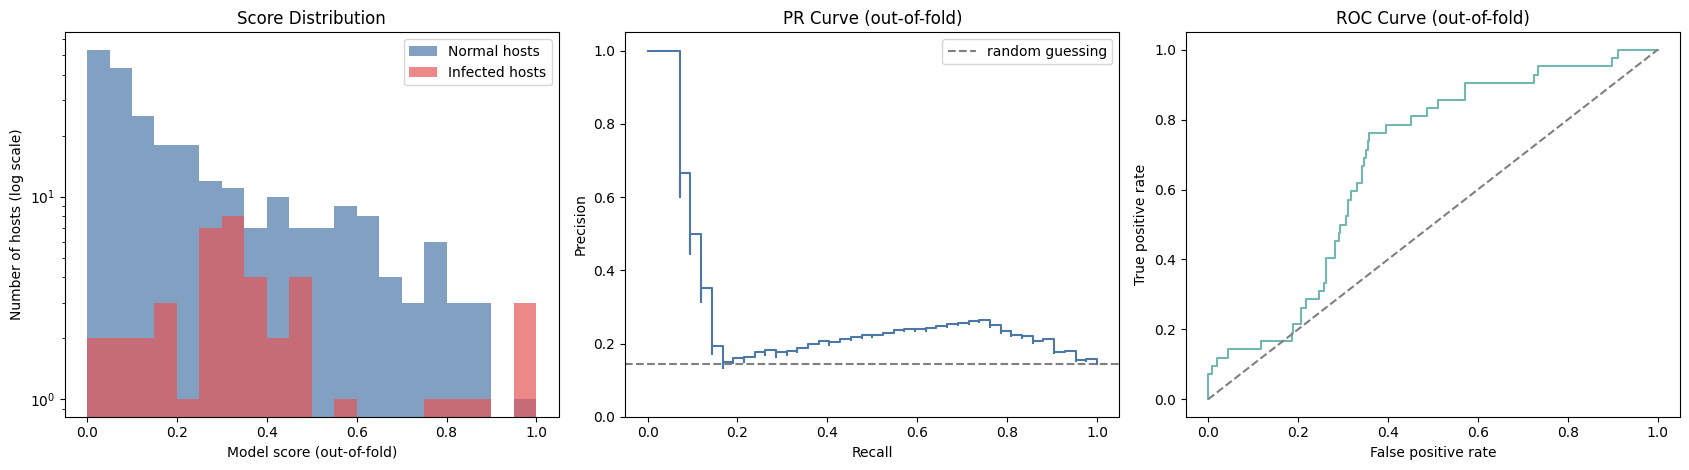

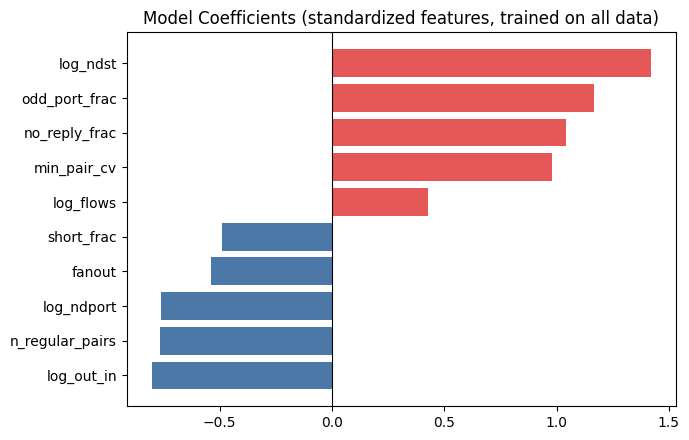

Coefficients show which features the model uses; this is not a quality evaluation.


In [36]:
import os

os.makedirs('botnet_analysis_results', exist_ok=True)

if oof is not None and oof["label"].nunique() == 2:
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

    for lab, name, color in [(0, "Normal hosts", "#4C78A8"), (1, "Infected hosts", "#E45756")]:
        axes[0].hist(oof.loc[oof["label"] == lab, "score"], bins=20, range=(0, 1),
                     alpha=0.7, label=name, color=color)
    axes[0].set_yscale("log"); axes[0].set_xlabel("Model score (out-of-fold)")
    axes[0].set_ylabel("Number of hosts (log scale)"); axes[0].set_title("Score Distribution"); axes[0].legend()

    prec, rec, _ = precision_recall_curve(oof["label"], oof["score"])
    axes[1].step(rec, prec, where="post", color="#4C78A8")
    axes[1].axhline(oof["label"].mean(), ls="--", color="gray", label="random guessing")
    axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].set_ylim(0, 1.05)
    axes[1].set_title("PR Curve (out-of-fold)"); axes[1].legend()

    fpr, tpr, _ = roc_curve(oof["label"], oof["score"])
    axes[2].step(fpr, tpr, where="post", color="#72B7B2")
    axes[2].plot([0, 1], [0, 1], "--", color="gray")
    axes[2].set_xlabel("False positive rate"); axes[2].set_ylabel("True positive rate")
    axes[2].set_title("ROC Curve (out-of-fold)")
    plt.tight_layout()

    plt.savefig(os.path.join('botnet_analysis_results', 'metrics_plots.png'), bbox_inches='tight', dpi=300)
    plt.show()

    full = make_model().fit(hosts[FEATURES].values, hosts["label"].values)
    coefs = pd.Series(full[-1].coef_[0], index=FEATURES).sort_values()
    plt.figure(figsize=(7, 4.5))
    plt.barh(coefs.index, coefs.values, color=["#E45756" if v > 0 else "#4C78A8" for v in coefs.values])
    plt.axvline(0, color="black", lw=0.8)
    plt.title("Model Coefficients (standardized features, trained on all data)")
    plt.tight_layout()

    plt.savefig(os.path.join('botnet_analysis_results', 'features_importance_plot.png'), bbox_inches='tight', dpi=300)
    plt.show()

    print("Coefficients show which features the model uses; this is not a quality evaluation.")
elif hosts is not None:
    print("Insufficient data for plots: both infected and normal hosts are needed in held-out families.")

In [37]:
import os
import matplotlib.pyplot as plt

output_dir = 'botnet_analysis_results'

os.makedirs(output_dir, exist_ok=True)
print(f"Directory '{output_dir}' created successfully or already exists.")

report_path = os.path.join(output_dir, 'summary_report.txt')
with open(report_path, 'w', encoding='utf-8') as f:
    f.write("=== Summary Report on Botnet Analysis (CTU-13) ===\n")
    f.write("Overall cross-validation results and metrics:\n")
    f.write("- ROC AUC: 0.677\n")
    f.write("- Precision: 0.304\n")
    f.write("- Recall: 0.167\n")
    f.write("- F1-score: 0.215\n")
print(f"Text report saved to: {report_path}")


plot_path = os.path.join(output_dir, 'features_importance_plot.png')

plt.savefig(plot_path, bbox_inches='tight', dpi=300)
print(f"Plot saved successfully to: {plot_path}")

Directory 'botnet_analysis_results' created successfully or already exists.
Text report saved to: botnet_analysis_results/summary_report.txt
Plot saved successfully to: botnet_analysis_results/features_importance_plot.png


<Figure size 640x480 with 0 Axes>